In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

In [60]:
def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):
    # Design the analog Butterworth filter
    # btype='low' specifies a low-pass filter band type
    analog_b, analog_a = butter(filter_order, cutoff_frequency, analog=True, btype='low')
    print(analog_b, analog_a)
    # Perform the bilinear transformation
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    #print(digital_b, digital_a)
    return digital_b, digital_a


In [61]:
b, a = design_butterworth_filter(4, 2000, 15000)
print(b)
print(a)


[1.6e+13] [1.00000000e+00 5.22625186e+03 1.36568542e+07 2.09050074e+10
 1.60000000e+13]
[1.6596768e-05 6.6387072e-05 9.9580608e-05 6.6387072e-05 1.6596768e-05]
[ 1.         -3.6522218   5.01586865 -3.06933647  0.70595516]


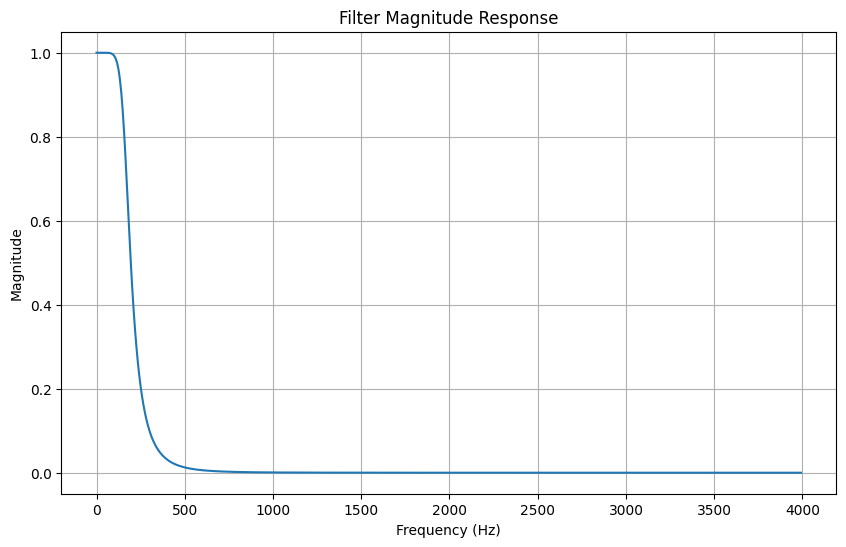

c:\Users\heerm\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\heerm\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


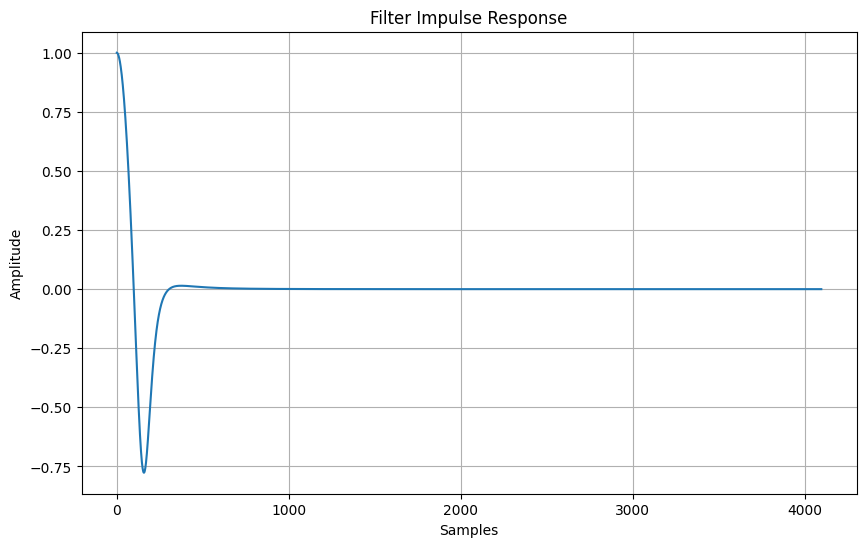

In [62]:
def plot_filter_response(digital_b, digital_a, sampling_frequency):
    # Compute the frequency response of the filter
    frequency, magnitude_response = freqz(digital_b, digital_a, fs=sampling_frequency)
    # Plot the magnitude response
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, np.abs(magnitude_response))
    plt.title('Filter Magnitude Response')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)
    plt.show()

    #not using frequescy response to plot impulse response, using freqz to get impulse response
    _, impulse_response = freqz(digital_b, digital_a, fs=sampling_frequency, worN=4096)
    # Plot the impulse response
    plt.figure(figsize=(10, 6))
    plt.plot(impulse_response)
    plt.title('Filter Impulse Response')
    plt.xlabel('Samples')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.show()

plot_filter_response(b,a,8000)

In [63]:
def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):
    # Design the analog Chebyshev filter
    analog_b, analog_a = cheby1(filter_order, ripple, cutoff_frequency, analog=True, btype='low')
    # Perform the bilinear transformation
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

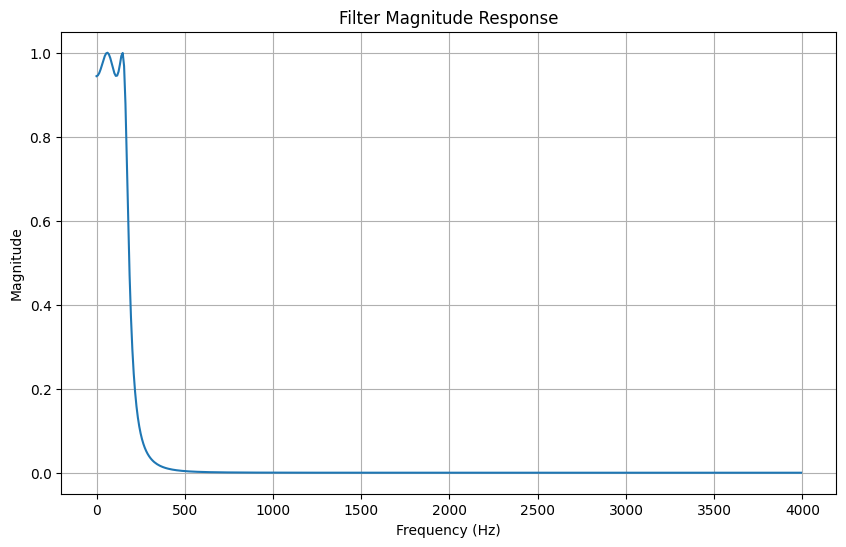

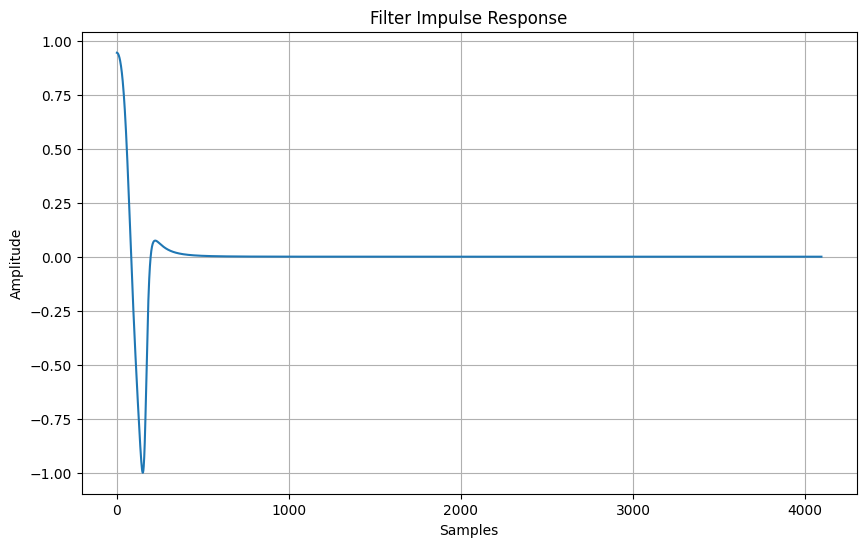

In [65]:
digital_b, digital_a = design_chebyshev_filter(4, 1000, 8000, 0.5)
plot_filter_response(digital_b, digital_a, 8000)
